<center><h1>Ho_LiYuan_HW3</h1></center>
<br>
<br>

Name: Li Yuan Ho
<br>
Github Username: lyuanh0
<br>
USC ID: 2540643454

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Get the AReM Data Set

In [2]:
folders = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']

def load_arem_file(filepath):
    rows = []
    with open(filepath, 'r') as f:
        for line in f:
            if line.startswith('#') or not line.strip():
                continue
            # Extracts all numeric values regardless of spaces, commas, or trailing delimiters
            nums = re.findall(r'[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?', line)
            if len(nums) >= 7:
                rows.append([float(x) for x in nums[1:7]])  # Skips time column
                
    return pd.DataFrame(rows, columns=['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'])

all_data = {}

for folder in folders:
    folder_path = f"../data/AReM/{folder}"
    csv_files = [f for f in os.listdir(folder_path) if f.startswith('dataset') and f.endswith('.csv')]
    for f in csv_files:
        full_path = f"{folder_path}/{f}"
        all_data[(folder, f)] = load_arem_file(full_path)

### (b) Test and Train Data
Datasets 1 and 2 in folders bending1 and bending 2, as well as datasets 1, 2, and 3 in other folders as test data  
and other datasets as train data.

In [3]:
train_data = {}
test_data = {}

for (folder, f), df in all_data.items():
    if folder in ['bending1', 'bending2']:
        test_names = ['dataset1.csv', 'dataset2.csv']
    else:
        test_names = ['dataset1.csv', 'dataset2.csv', 'dataset3.csv']
        
    if f in test_names:
        test_data[(folder, f)] = df
    else:
        train_data[(folder, f)] = df

### (c) Feature Extraction
Classification of time series usually needs extracting features from them. In this problem, we focus on time-domain features.

#### i. Research
Research what types of time-domain features are usually used in time series classification and list them (examples are minimum, maximum, mean, etc).

- Minimum and maximum: Smallest and largest values in the time series
- Mean (Average): The average of the data
- Median: The middle value of the ordered data, also the value of 50th percentile of the data
- Range: max-min
- First Quartile: $Q_1$, 25th percentile
- Third Quartile: $Q_3$, 75th percentile
- Interquartile Range: $\text{IQR} = Q_3 - Q_1$
- Variance and Standard Deviation: Measures of data dispersion around the mean (spread or volatility within the series)
- Skewness: Measure of the asymmetry of the data distribution
- Kurtosis: Peakedness and heavy-tailedness of the distribution
- Autocorrelation: Measures the correlation between the time series and lagged versions of itself (for patterns or periodicity)

#### ii. Extraction
Extract the time-domain features minimum, maximum, mean, median, standard deviation, first quartile, and third quartile for all of the 6 time series in each instance. You are free to normalize/standardize features or use them directly.

In [4]:
feature_rows = []
instance_labels = []

# Iterate through 88 instances in dataset
for (folder, filename), df in all_data.items():
    row_features = {}
    
    # 6 time series
    for i, col in enumerate(df.columns, start=1):
        row_features[f'min_{i}'] = df[col].min()
        row_features[f'max_{i}'] = df[col].max()
        row_features[f'mean_{i}'] = df[col].mean()
        row_features[f'median_{i}'] = df[col].median()
        row_features[f'std_{i}'] = df[col].std()
        row_features[f'1st_quart_{i}'] = df[col].quantile(0.25)
        row_features[f'3rd_quart_{i}'] = df[col].quantile(0.75)
        
    feature_rows.append(row_features)
    instance_labels.append(f"{folder}_{filename}")

# Construct DataFrame (88 rows x 42 feature columns)
features_df = pd.DataFrame(feature_rows)
features_df.insert(0, 'Instance', range(1, len(features_df) + 1))
display(features_df)

,Instance,min_1,max_1,mean_1,median_1,std_1,1st_quart_1,3rd_quart_1,min_2,max_2,...,std_5,1st_quart_5,3rd_quart_5,min_6,max_6,mean_6,median_6,std_6,1st_quart_6,3rd_quart_6
0,1,36.25,48.00,43.969125,44.500,1.618364,43.31,44.67,0.0,1.50,...,3.318301,20.5000,23.75,0.00,2.96,0.555312,0.490,0.487826,0.0000,0.8300
1,2,37.00,48.00,43.454958,43.250,1.386098,42.50,45.00,0.0,1.58,...,2.488862,22.2500,24.00,0.00,5.26,0.679646,0.500,0.622534,0.4300,0.8700
2,3,33.00,47.75,42.179812,43.500,3.670666,39.15,45.00,0.0,3.00,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.500,0.524317,0.0000,1.0000
3,4,33.00,45.75,41.678063,41.750,2.243490,41.33,42.75,0.0,2.83,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.430,0.389164,0.0000,0.5000
4,5,37.25,45.00,40.624792,40.500,1.476967,39.25,42.00,0.0,1.30,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.430,0.582915,0.0000,1.3000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,19.75,45.50,34.322750,35.250,4.752477,31.00,38.00,0.0,13.47,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.200,1.732727,2.1575,4.5650
84,85,19.25,44.00,34.473188,35.000,4.796705,31.25,38.00,0.0,13.86,...,3.156320,13.7300,17.75,0.43,9.00,3.340458,3.090,1.699114,2.1200,4.3750
85,86,23.50,46.25,34.873229,35.250,4.531720,31.75,38.25,0.0,14.82,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.270,1.690960,2.1700,4.5000
86,87,18.33,45.75,34.599875,35.125,4.731790,31.50,38.00,0.0,15.37,...,2.905688,14.0000,18.25,0.00,8.86,3.289542,3.015,1.680170,2.1200,4.2600


#### iii. Standard Deviation
Estimate the standard deviation of each of the time-domain features you
extracted from the data. Then, use Python’s bootstrapped or any other
method to build a 90% bootsrap confidence interval for the standard deviation
of each feature.

In [5]:
# Standard deviation
if 'Instance' in features_df.columns:
    X = features_df.drop(columns=['Instance'])
else:
    X = features_df.copy()

X = X.apply(pd.to_numeric)

# Compute standard deviation
std_df = pd.DataFrame({
    'Feature': X.columns,
    'Std_Dev': X.std(ddof=1).values
})

display(std_df)

,Feature,Std_Dev
0,min_1,9.569975
1,max_1,4.394362
2,mean_1,5.335718
3,median_1,5.440054
4,std_1,1.772153
5,1st_quart_1,6.153590
6,3rd_quart_1,5.138925
7,min_2,0.000000
8,max_2,5.062729
9,mean_2,1.574164


In [6]:
# Bootstrap confidence interval
boot_confid = []

for col in X.columns:
    boot_stds = []
    n = len(X) # 88
    for i in range(1000):
        bootstrap_sample = np.random.choice(X[col], size=n, replace=True)        # Resample 88 items from column 
        sample_std = np.std(bootstrap_sample, ddof=1)        # Standard deviation (ddof=1: divide by N - 1)
        boot_stds.append(sample_std)

    boot_confid.append({
        'Feature': col,
        'Lower Bound': np.percentile(boot_stds, 5),
        'Upper Bound': np.percentile(boot_stds, 95)
    })

summary_df = std_df.merge(pd.DataFrame(boot_confid), on='Feature')
display(summary_df)

,Feature,Std_Dev,Lower Bound,Upper Bound
0,min_1,9.569975,8.257483,10.869210
1,max_1,4.394362,3.310258,5.310997
2,mean_1,5.335718,4.686830,5.887648
3,median_1,5.440054,4.806024,6.013860
4,std_1,1.772153,1.578068,1.953080
5,1st_quart_1,6.153590,5.597842,6.624274
6,3rd_quart_1,5.138925,4.311214,5.847937
7,min_2,0.000000,0.000000,0.000000
8,max_2,5.062729,4.634045,5.411484
9,mean_2,1.574164,1.391881,1.706986


#### iv. Select Features
Use your judgement to select the three most important time-domain features
(one option may be min, mean, and max)

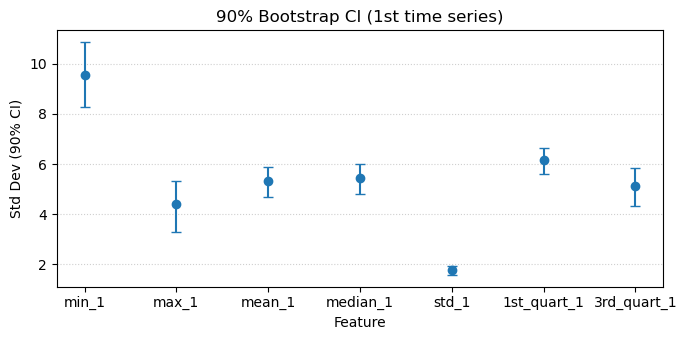

In [7]:
# Filter to 7 summary features of 1st time series
sensor1_summary = summary_df[summary_df['Feature'].str.endswith('_1')].copy()

# Asymmetric error margins
yerr = [
    sensor1_summary['Std_Dev'] - sensor1_summary['Lower Bound'],
    sensor1_summary['Upper Bound'] - sensor1_summary['Std_Dev']
]

plt.figure(figsize=(7, 3.5))
plt.errorbar(
    x=sensor1_summary['Feature'],
    y=sensor1_summary['Std_Dev'],
    yerr=yerr,
    fmt='o',
    capsize=3.5,
)

plt.title('90% Bootstrap CI (1st time series)')
plt.xlabel('Feature')
plt.ylabel('Std Dev (90% CI)')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Using the 90% bootstrap confidence interval error bar plot in support of selection, my selected time-domain features are **Mean**, **Median**, and **Standard Deviation**:

1. **Mean:** It shows a tight and stable confidence interval across instances. The mean can capture the data's overall central baseline.  
2. **Median:** Has a narrow confidence interval similar to the mean. The median can measure the central strength while not being affected by the outliers.  
3. **Standard Deviation:** It displays the narrowest, most consistent confidence interval in the plot. It gives an insight to the data distribution while also showing how many datapoints are away from the mean. 

## 2. ISLR 3.7.4
I collect a set of data (n = 100 observations) containing a single
predictor and a quantitative response. I then fit a linear regression
model to the data, as well as a separate cubic regression, i.e. Y =
β0 + β1X + β2X^2 + β3X^3 + ϵ.

### (a) Linear Train
Suppose that the true relationship between X and Y is linear,
i.e. Y = β0 + β1X + ϵ. Consider the training residual sum of
squares (RSS) for the linear regression, and also the training
RSS for the cubic regression. Would we expect one to be lower
than the other, would we expect them to be the same, or is there
not enough information to tell? Justify your answer.

We would expect the **training RSS for cubic regression to be smaller than the training RSS for linear regression.**  

The cubic regression model has better flexibility and will better fit to the training data. This means a lower RSS value than the linear regression's RSS.

### (b) Linear Test
Answer (a) using test rather than training RSS.

We would expect the **test RSS for linear regression to be smaller than the test RSS for cubic regression.**  

As the true relationship is linear, the cubic model will overfit the training data with the random error. This will increase the model variance without reducing bias and result in poorer predictions than the predictions of the linear model.

### (c) Not Linear Train
Suppose that the true relationship between X and Y is not linear,
but we don’t know how far it is from linear. Consider the training
RSS for the linear regression, and also the training RSS for the
cubic regression. Would we expect one to be lower than the
other, would we expect them to be the same, or is there not
enough information to tell? Justify your answer.

We would expect the **training RSS for cubic regression to be smaller than the training RSS for linear regression.**  

The cubic model still has more flexibility and will better fit the training data. Thus, it will still have a lower training RSS than the linear's model.

### (d) Not Linear Testing
Answer (c) using test rather than training RSS.

**It cannot be certain with the information we currently have.**  

Since we do not know how far it is from linear, the results can be different depending on the relationship. 
The test RSS of the linear model can be lower than the cubic regression if the relationship is closer to linear, or if it is far from linear, it could give a lower RSS for the cubic regression than the linear regression instead.
